# Deep Sea Treasure: environment exploration

Goal: get comfortable with `mo-gymnasium`'s `deep-sea-treasure-v0` before implementing SFOLS (Alegre et al., 2022).

We'll:
1. Inspect the env's spaces and map.
2. Visualize the grid and a random rollout.
3. Look at the ground-truth convex coverage set (CCS) the paper reports (10 treasures).
4. Reproduce the "PWLC curve + corner weights" picture from Figure 1 of the paper, using the known front.
5. Train single-policy tabular Q-learning for a fixed preference weight `w`, and check that the greedy policy it finds lands on the treasure the ground-truth CCS predicts for that `w`.

In [ ]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import mo_gymnasium as mo_gym

np.set_printoptions(suppress=True, precision=3)

## 1. Create the environment and inspect it

`deep-sea-treasure-v0`'s default map is the *convex* map from Yang et al. (2019), the one the SFOLS paper uses (Appendix B.1, footnote 8). The reward is a 2D vector: `[treasure_value, time_penalty]`, where `time_penalty` is always `-1`.

In [ ]:
env = mo_gym.make("deep-sea-treasure-v0")
core = env.unwrapped

print("Observation space:", core.observation_space)
print("Action space:", core.action_space, "-> 0=up, 1=down, 2=left, 3=right")
print("Reward space (vector):", core.reward_space)
print("Map shape:", core.sea_map.shape)
print("Max episode steps:", env.spec.max_episode_steps)
print("\nMap (0 = empty sea, -10 = deep sea/no treasure, >0 = treasure value):")
print(core.sea_map)

Observation space: Box(0, 11, (2,), int32)
Action space: Discrete(4) -> 0=up, 1=down, 2=left, 3=right
Reward space (vector): Box([ 0. -1.], [23.7 -1. ], (2,), float32)
Map shape: (11, 11)
Max episode steps: 100

Map (0 = empty sea, -10 = deep sea/no treasure, >0 = treasure value):
[[  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0. ]
 [  0.7   0.    0.    0.    0.    0.    0.    0.    0.    0.    0. ]
 [-10.    8.2   0.    0.    0.    0.    0.    0.    0.    0.    0. ]
 [-10.  -10.   11.5   0.    0.    0.    0.    0.    0.    0.    0. ]
 [-10.  -10.  -10.   14.   15.1  16.1   0.    0.    0.    0.    0. ]
 [-10.  -10.  -10.  -10.  -10.  -10.    0.    0.    0.    0.    0. ]
 [-10.  -10.  -10.  -10.  -10.  -10.    0.    0.    0.    0.    0. ]
 [-10.  -10.  -10.  -10.  -10.  -10.   19.6  20.3   0.    0.    0. ]
 [-10.  -10.  -10.  -10.  -10.  -10.  -10.  -10.    0.    0.    0. ]
 [-10.  -10.  -10.  -10.  -10.  -10.  -10.  -10.   22.4   0.    0. ]
 [-10.  -10.  -10.  -10.  -1

/Users/guillemmasdemont/Documents/Master/Summer-Research/MORL/venv/lib/python3.13/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


## 2. Visualize the map

The agent (submarine) starts at `(0, 0)` (top-left). Cells marked `-10` are impassable rock (moving into one is a no-op, staying in place but still costing a time step); `0` cells are open sea; any cell `> 0` is a treasure and ends the episode on arrival. The rock forces the agent along the staircase-shaped corridor of valid cells.

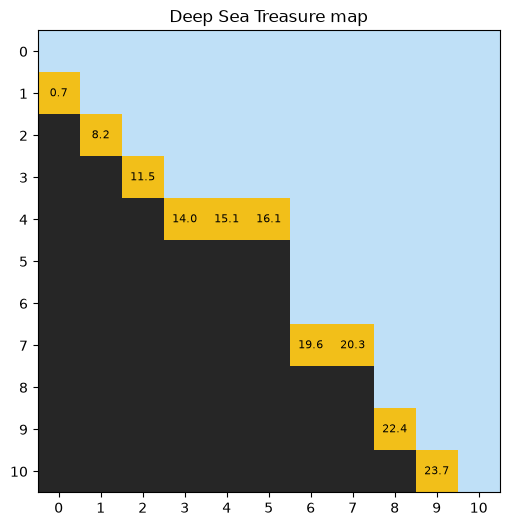

In [3]:
def plot_map(ax, sea_map, path=None, title=None):
    rows, cols = sea_map.shape
    # color: rock=black, sea=lightblue, treasure=gold
    color_grid = np.zeros((rows, cols, 3))
    for r in range(rows):
        for c in range(cols):
            v = sea_map[r, c]
            if v == -10:
                color_grid[r, c] = (0.15, 0.15, 0.15)
            elif v > 0:
                color_grid[r, c] = (0.95, 0.75, 0.1)
            else:
                color_grid[r, c] = (0.75, 0.88, 0.97)
    ax.imshow(color_grid)
    for r in range(rows):
        for c in range(cols):
            if sea_map[r, c] > 0:
                ax.text(c, r, f"{sea_map[r, c]:.1f}", ha="center", va="center", fontsize=8)
    if path is not None:
        ys = [p[0] for p in path]
        xs = [p[1] for p in path]
        ax.plot(xs, ys, color="crimson", linewidth=2, marker="o", markersize=4)
        ax.plot(xs[0], ys[0], marker="*", color="black", markersize=14)  # start
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(title or "")


fig, ax = plt.subplots(figsize=(6, 6))
plot_map(ax, core.sea_map, title="Deep Sea Treasure map")
plt.show()

## 3. Random rollout

A helper to roll out any `obs -> action` policy function and collect the visited states + vector rewards, then plot the resulting path on the map.

0
0
0
2
1
Random rollout: 5 steps, vector return (undiscounted) = [ 0.7 -5. ]


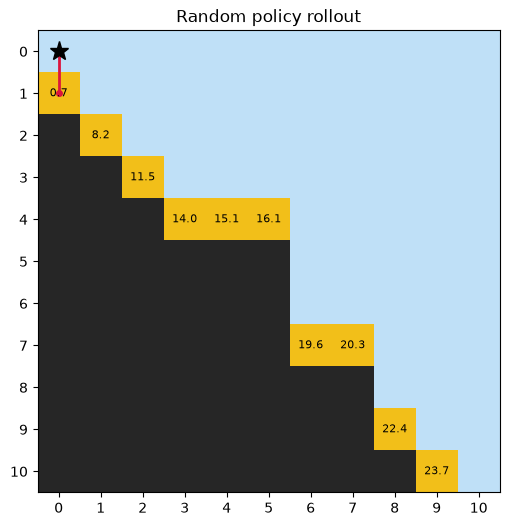

In [15]:
def rollout(env, policy_fn, max_steps=100, seed=None):
    obs, info = env.reset(seed=seed)
    states = [tuple(int(x) for x in obs)]
    rewards = []
    for _ in range(max_steps):
        action = policy_fn(obs)
        print(action)
        obs, reward, terminated, truncated, info = env.step(action)
        states.append(tuple(int(x) for x in obs))
        rewards.append(reward)
        if terminated or truncated:
            break
    return states, rewards


rng = random.Random(2)
random_policy = lambda obs: rng.randrange(core.action_space.n)
path, rewards = rollout(env, random_policy, seed=0)
vec_return = np.sum(rewards, axis=0)

print(f"Random rollout: {len(path) - 1} steps, vector return (undiscounted) = {vec_return}")

fig, ax = plt.subplots(figsize=(6, 6))
plot_map(ax, core.sea_map, path=path, title="Random policy rollout")
plt.show()

## 4. Ground-truth convex coverage set (CCS)

`core.pareto_front(gamma)` returns the 10 known-optimal `[discounted_treasure, discounted_time_penalty]` vectors — one per treasure — matching the CCS the paper reports for this domain (Section 5, "Deep Sea Treasure"). We use `gamma=0.99`, the discount factor the paper uses for DST (Appendix B.1). This is our ground truth to check any learned CCS against later.

Ground-truth CCS (discounted [treasure, time] vectors):
[ 0.7 -1. ]
[ 8.037 -2.97 ]
[11.047 -4.901]
[13.181 -6.793]
[14.074 -7.726]
[14.856 -8.648]
[ 17.373 -12.248]
[ 17.814 -13.125]
[ 19.073 -15.706]
[ 19.778 -17.383]


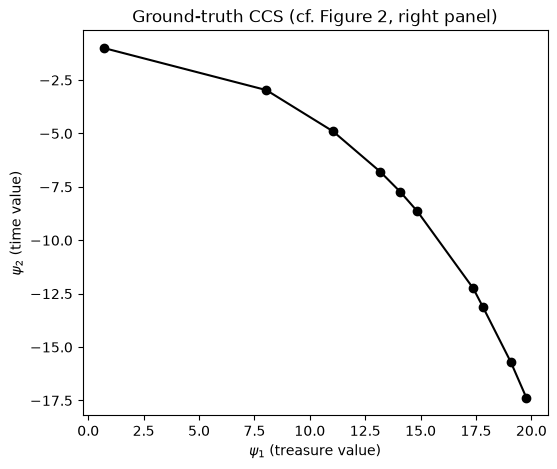

In [16]:
GAMMA = 0.99
front = np.array(core.pareto_front(gamma=GAMMA))
print("Ground-truth CCS (discounted [treasure, time] vectors):")
for v in front:
    print(v)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(front[:, 0], front[:, 1], "o-", color="black")
ax.set_xlabel(r"$\psi_1$ (treasure value)")
ax.set_ylabel(r"$\psi_2$ (time value)")
ax.set_title("Ground-truth CCS (cf. Figure 2, right panel)")
plt.show()

## 5. The PWLC value curve and corner weights (Figure 1)

For a 2-objective domain, weights are `w = [w0, 1 - w0]`. For each `w0` we plot
$$v^{SMP}_w = \max_{\psi^\pi \in \text{CCS}} \psi^\pi \cdot w,$$
i.e. the upper envelope of the 10 lines `ψ · w`, one per treasure. This is the piecewise-linear convex (PWLC) curve from Section 4 / Figure 1 of the paper. The points where the arg-max switches from one treasure to another are the **corner weights** — exactly the tasks SFOLS prioritizes learning next.

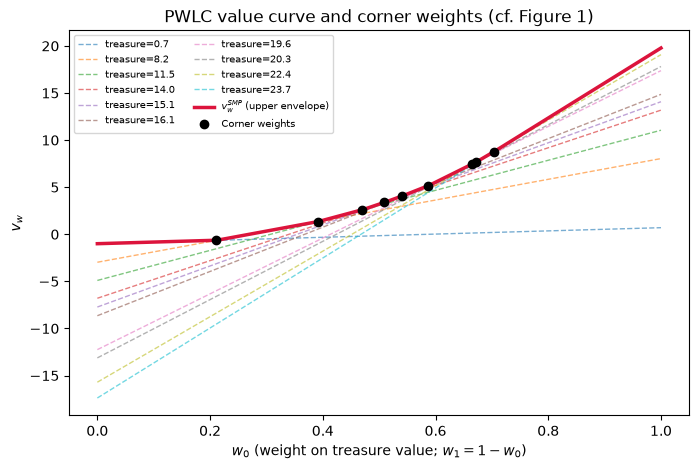

Corner weights (w0): [0.21  0.391 0.469 0.509 0.541 0.587 0.665 0.671 0.703]


In [17]:
w0_grid = np.linspace(0, 1, 500)
weights = np.stack([w0_grid, 1 - w0_grid], axis=1)  # (500, 2)
values_per_policy = weights @ front.T  # (500, 10): v_w for each of the 10 CCS policies
v_smp = values_per_policy.max(axis=1)
best_policy = values_per_policy.argmax(axis=1)

# corner weights: where the arg-max policy switches
switch_idx = np.where(np.diff(best_policy) != 0)[0]
corner_w0 = w0_grid[switch_idx]

treasure_values = sorted(core.sea_map[core.sea_map > 0])

fig, ax = plt.subplots(figsize=(8, 5))
for i, treasure in enumerate(treasure_values):
    ax.plot(w0_grid, values_per_policy[:, i], "--", linewidth=1, alpha=0.6, label=f"treasure={treasure:.1f}")
ax.plot(w0_grid, v_smp, color="crimson", linewidth=2.5, label=r"$v^{SMP}_w$ (upper envelope)")
ax.scatter(corner_w0, v_smp[switch_idx], color="black", zorder=5, label="Corner weights")
ax.set_xlabel(r"$w_0$ (weight on treasure value; $w_1 = 1-w_0$)")
ax.set_ylabel(r"$v_w$")
ax.set_title("PWLC value curve and corner weights (cf. Figure 1)")
ax.legend(loc="upper left", fontsize=7, ncol=2)
plt.show()

print("Corner weights (w0):", np.round(corner_w0, 3))

## 6. Tabular Q-learning for a fixed scalarized reward

For a fixed weight `w`, scalarize the vector reward as `r · w` and run plain tabular Q-learning (this is the single-policy special case of Algorithm 4 in the paper, without GPI warm-starting or an SF vector — just a scalar Q-table).

**Note on exploration:** DST is a sparse-reward, long-horizon domain — the best treasures require ~15-19 consecutive correct moves from the start, with zero reward until arrival. Zero-initialized Q-values converge to a nearby, easy-to-find treasure and never discover farther, better ones (verified below by comparing against shortest-path discounted values). Optimistic initialization (`Q0 = 25`, above the max possible treasure) fixes this by making the agent keep probing unvisited actions instead of exploiting an early lucky find.

3
1
3
1
1
w=[0.4 0.6]: greedy policy reaches (3, 2) in 5 steps, undiscounted return=[11.5 -5. ]


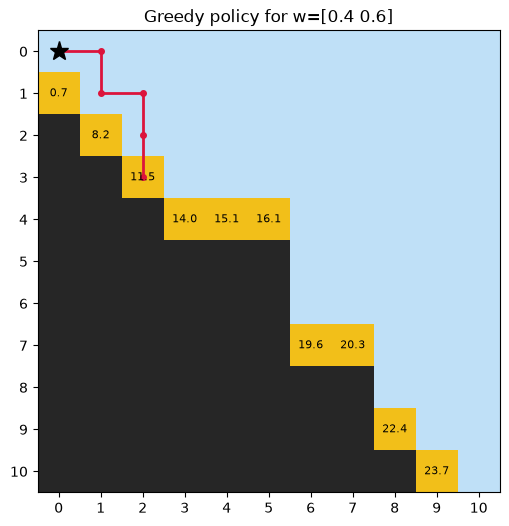

In [21]:
def q_learning(env, w, num_steps, alpha=0.1, gamma=GAMMA, eps_start=1.0, eps_end=0.05, q_init=25.0, seed=0):
    """Tabular Q-learning on the scalarized reward r . w. q_init > max treasure value
    gives optimistic initialization, needed for DST's sparse/long-horizon exploration."""
    rng = random.Random(seed)
    q = defaultdict(lambda: np.full(env.action_space.n, q_init))
    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / (0.5 * num_steps))
        if rng.random() < eps:
            action = rng.randrange(env.action_space.n)
        else:
            action = int(np.argmax(q[state]))
        next_obs, reward, terminated, truncated, _ = env.step(action)
        scalar_r = float(np.dot(reward, w))
        next_state = tuple(int(x) for x in next_obs)
        best_next = 0.0 if terminated else np.max(q[next_state])
        q[state][action] += alpha * (scalar_r + gamma * best_next - q[state][action])
        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(int(x) for x in obs)
        else:
            state = next_state
    return q


def greedy_policy(q):
    return lambda obs: int(np.argmax(q[tuple(int(x) for x in obs)]))


# Train for w = [1, 0] (only treasure value matters, time penalty ignored)
w = np.array([0.4, 0.6])
q = q_learning(env, w, num_steps=100_000, seed=1)
path, rewards = rollout(env, greedy_policy(q), seed=1)
vec_return = np.sum(rewards, axis=0)
print(f"w={w}: greedy policy reaches {path[-1]} in {len(path)-1} steps, undiscounted return={vec_return}")

fig, ax = plt.subplots(figsize=(6, 6))
plot_map(ax, core.sea_map, path=path, title=f"Greedy policy for w={w}")
plt.show()

## 7. Sanity check: learned policies vs. corner weights

Train independently for several `w0` values that straddle the corner weights found in Section 5, and check that the treasure each greedy policy reaches matches the CCS-optimal treasure predicted for that `w0`. This is the same check SFOLS relies on (Theorem 4.1): each segment between corner weights shares one optimal policy.

In [22]:
treasure_rows, treasure_cols = np.where(core.sea_map > 0)
treasure_by_pos = {
    (int(r), int(c)): float(core.sea_map[r, c]) for r, c in zip(treasure_rows, treasure_cols)
}

# midpoints between consecutive corner weights (plus the two segment endpoints) -> one test weight per CCS segment
boundaries = np.concatenate([[0.0], corner_w0, [1.0]])
test_w0s = (boundaries[:-1] + boundaries[1:]) / 2

results = []
for w0 in test_w0s:
    w = np.array([w0, 1 - w0])
    predicted_idx = best_policy[np.argmin(np.abs(w0_grid - w0))]
    predicted_treasure = treasure_values[predicted_idx]

    q = q_learning(env, w, num_steps=100_000, seed=2)
    path, rewards = rollout(env, greedy_policy(q), seed=2)
    learned_treasure = treasure_by_pos.get(path[-1], None)

    results.append((w0, predicted_treasure, learned_treasure))
    match = "OK" if learned_treasure == predicted_treasure else "MISMATCH"
    print(f"w0={w0:.3f}  predicted={predicted_treasure:5.1f}  learned={learned_treasure}  [{match}]")

1
w0=0.105  predicted=  0.7  learned=0.7  [OK]
3
1
1
w0=0.301  predicted=  8.2  learned=8.2  [OK]
3
1
3
1
1
w0=0.430  predicted= 11.5  learned=11.5  [OK]
3
1
3
1
3
1
1
w0=0.489  predicted= 14.0  learned=14.0  [OK]
3
1
3
1
3
1
3
1
w0=0.525  predicted= 15.1  learned=15.1  [OK]
3
1
3
1
3
1
3
3
1
w0=0.564  predicted= 16.1  learned=16.1  [OK]
3
3
1
3
1
1
3
3
3
1
1
1
1
w0=0.626  predicted= 19.6  learned=19.6  [OK]
3
3
1
1
3
3
3
3
3
1
1
1
1
1
w0=0.668  predicted= 20.3  learned=20.3  [OK]
3
3
3
1
3
1
1
3
3
1
1
1
3
3
1
1
1
w0=0.687  predicted= 22.4  learned=22.4  [OK]
3
3
3
1
3
3
3
3
1
3
1
1
1
3
1
1
1
1
1
w0=0.852  predicted= 23.7  learned=23.7  [OK]
